# PS3 — Building a Statewide Coordination Model for New Jersey Youth Football

## Project Purpose

New Jersey has many independent community youth football organizations. They operate locally and participate in different leagues, but there is no single statewide structure connecting all of them.

This project uses GIS to test whether a proposed organization called the **New Jersey Youth and Amateur Sports Association (NJYASA)** could create a practical statewide structure.

The proposed model would organize participating programs through:

1. **Local organizations**
2. **21 County Conferences**
3. **Three regions: North, Central, and South**

Each County Conference would elect one president. The seven County Presidents within each region would form that region's representative council.

Professional NJYASA staff would work from the statewide and regional levels to coordinate partnerships, resources, and services.

### Main Research Question

**Could a county-based and regional structure provide a practical way to coordinate New Jersey youth football organizations and connect them with public and community resources?**

### What This Project Examines

- Where youth football organizations are located
- How they are currently organized into leagues
- Whether North, Central, and South regions make geographic sense
- What each proposed County Conference would represent
- Whether colleges and other institutions are positioned to support this structure

### Important Limitation

This project tests the geographic and administrative feasibility of the proposed structure. It does not assume that any organization, college, business, or government agency has agreed to participate.

In [ ]:
# -------------------------------------------------------
# PS3 - SETUP
# -------------------------------------------------------

import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt

print("GIS setup complete.")

GIS setup complete.


In [ ]:
# -------------------------------------------------------
# PS3 - DATA SOURCES
# -------------------------------------------------------

# Official New Jersey county boundaries
COUNTY_URL = (
    "https://services2.arcgis.com/XVOqAjTOJ5P6ngMu/"
    "arcgis/rest/services/NJ_Counties_3424/"
    "FeatureServer/0/query?"
    "where=1%3D1&outFields=*&returnGeometry=true&"
    "outSR=4326&f=geojson"
)

# Youth football research dataset
FOOTBALL_URL = (
    "https://raw.githubusercontent.com/"
    "Dunk0725/GIS-26/"
    "NJ-Youth-Football-GIS/"
    "PS3_NJ_Youth_Football_Analysis_Ready_2026.csv"
)

print("Data sources ready.")

Data sources ready.


In [ ]:
# -------------------------------------------------------
# PS3 - LOAD DATA
# -------------------------------------------------------

# Load NJ counties
counties = gpd.read_file(COUNTY_URL)

counties = counties[
    ["COUNTY", "geometry"]
].copy()

counties = counties.to_crs("EPSG:4326")

counties["COUNTY"] = (
    counties["COUNTY"]
    .astype(str)
    .str.strip()
    .str.title()
)


# Load youth football organizations
football = pd.read_csv(
    FOOTBALL_URL,
    dtype={"Program_ID": "string"}
)

football["Program_ID"] = (
    football["Program_ID"]
    .str.strip()
)


print("NJ counties:", len(counties))
print("Youth football organizations:", len(football))

NJ counties: 21
Youth football organizations: 266


In [ ]:
# -------------------------------------------------------
# PS3 - DATA CHECK
# -------------------------------------------------------

duplicate_ids = football["Program_ID"].duplicated().sum()

missing_coordinates = (
    football[
        ["Latitude", "Longitude"]
    ]
    .isna()
    .any(axis=1)
    .sum()
)

missing_league = (
    football["League_Acronym"]
    .isna()
    .sum()
)


print("Organizations:", len(football))
print("Duplicate IDs:", duplicate_ids)
print("Missing coordinates:", missing_coordinates)
print("League affiliation still pending:", missing_league)

Organizations: 266
Duplicate IDs: 0
Missing coordinates: 0
League affiliation still pending: 1


## Data Check

The working dataset contains **266 documented youth football organizations** with geographic coordinates.

One organization currently has a pending exact league affiliation. It remains included in the geographic analysis because its organization and field location are documented, but it will be treated separately when analyzing league membership.

## Where Are the Organizations?

The first step is to determine where the 266 documented organizations are located across New Jersey.

Each organization is converted into a GIS point using its home-field coordinates. Those points are then compared with official New Jersey county boundaries.

This provides an independent check that the researched county information matches the geographic location of each field.

In [ ]:
# -------------------------------------------------------
# PS3 - CREATE ORGANIZATION POINTS
# -------------------------------------------------------

football["Latitude"] = pd.to_numeric(
    football["Latitude"],
    errors="coerce"
)

football["Longitude"] = pd.to_numeric(
    football["Longitude"],
    errors="coerce"
)

football_points = gpd.GeoDataFrame(
    football.copy(),
    geometry=gpd.points_from_xy(
        football["Longitude"],
        football["Latitude"]
    ),
    crs="EPSG:4326"
)

print("Organization points created:", len(football_points))

Organization points created: 266


In [ ]:
# -------------------------------------------------------
# PS3 - CHECK ORGANIZATION COUNTIES
# -------------------------------------------------------

county_lookup = (
    counties[
        ["COUNTY", "geometry"]
    ]
    .rename(
        columns={
            "COUNTY": "GIS_County"
        }
    )
    .copy()
)

football_by_county = gpd.sjoin(
    football_points,
    county_lookup,
    how="left",
    predicate="within"
)

football_by_county = (
    football_by_county
    .drop(
        columns=["index_right"],
        errors="ignore"
    )
)


# Compare researched county with GIS county
football_by_county["County_Match"] = (
    football_by_county["Primary_County"]
    .astype(str)
    .str.strip()
    .str.lower()
    ==
    football_by_county["GIS_County"]
    .astype(str)
    .str.strip()
    .str.lower()
)


print("Organizations:", len(football_by_county))

print(
    "Missing GIS county:",
    football_by_county["GIS_County"].isna().sum()
)

print(
    "County matches:",
    football_by_county["County_Match"].sum()
)

print(
    "County differences:",
    (~football_by_county["County_Match"]).sum()
)

Organizations: 266
Missing GIS county: 0
County matches: 266
County differences: 0


In [ ]:
# -------------------------------------------------------
# PS3 - ORGANIZATIONS BY COUNTY
# -------------------------------------------------------

county_summary = (
    football_by_county
    .groupby("GIS_County")
    .size()
    .reset_index(
        name="Organizations"
    )
    .sort_values(
        "Organizations",
        ascending=False
    )
    .reset_index(drop=True)
)

county_summary["Statewide_Share"] = (
    county_summary["Organizations"]
    / len(football_by_county)
    * 100
).round(1)

display(county_summary)

,GIS_County,Organizations,Statewide_Share
0,Bergen,36,13.5
1,Monmouth,26,9.8
2,Morris,21,7.9
3,Burlington,19,7.1
4,Camden,18,6.8
5,Essex,18,6.8
6,Middlesex,16,6.0
7,Ocean,14,5.3
8,Union,14,5.3
9,Gloucester,13,4.9


### Why This Matters

The organizations are not evenly distributed across New Jersey.

Some counties contain many documented youth football organizations, while others contain relatively few. This difference becomes important later when considering County Conferences because every county would receive representation even though the number of organizations represented by each conference may differ substantially.

## Map 1 — Where Are New Jersey's Youth Football Organizations?

The first map shows the home-field location of each documented youth football organization in the dataset.

The purpose is to establish the statewide network before examining leagues or proposing a new administrative structure.

Each point represents one documented organization.

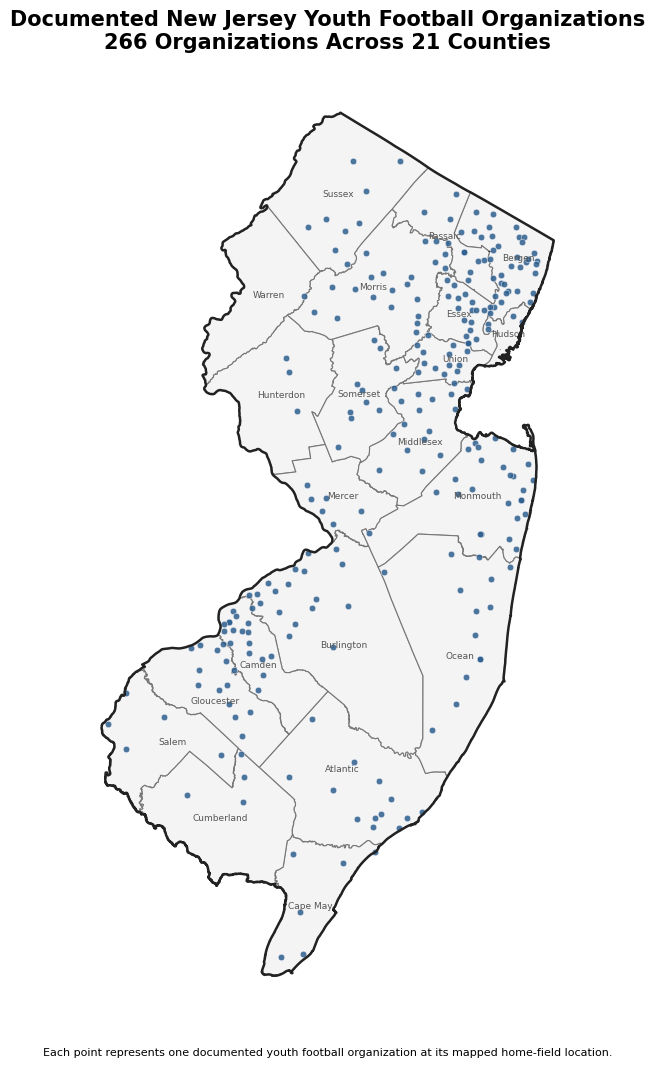

In [ ]:
# -------------------------------------------------------
# PS3 - MAP 1
# DOCUMENTED YOUTH FOOTBALL ORGANIZATIONS
# -------------------------------------------------------

# Use NJ State Plane for a cleaner map shape
map_counties = counties.to_crs("EPSG:3424")
map_points = football_by_county.to_crs("EPSG:3424")


# -------------------------------------------------------
# CREATE MAP
# -------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(9, 11)
)


# County background
map_counties.plot(
    ax=ax,
    color="#f4f4f4",
    edgecolor="#777777",
    linewidth=0.8
)


# Organization locations
map_points.plot(
    ax=ax,
    color="#2f5f8f",
    edgecolor="white",
    linewidth=0.35,
    markersize=22,
    alpha=0.85,
    zorder=3
)


# -------------------------------------------------------
# COUNTY LABELS
# -------------------------------------------------------

county_labels = map_counties.copy()

county_labels["label_point"] = (
    county_labels.geometry
    .representative_point()
)


for _, row in county_labels.iterrows():

    ax.text(
        row["label_point"].x,
        row["label_point"].y,
        row["COUNTY"],

        ha="center",
        va="center",

        fontsize=6.5,
        color="#555555",

        zorder=4
    )


# -------------------------------------------------------
# STRONGER STATE OUTLINE
# -------------------------------------------------------

state_outline = map_counties.dissolve()

state_outline.boundary.plot(
    ax=ax,
    color="#222222",
    linewidth=1.8,
    zorder=5
)


# -------------------------------------------------------
# TITLE
# -------------------------------------------------------

ax.set_title(
    "Documented New Jersey Youth Football Organizations\n"
    f"{len(map_points)} Organizations Across 21 Counties",
    fontsize=15,
    fontweight="bold",
    pad=15
)


# -------------------------------------------------------
# MAP NOTE
# -------------------------------------------------------

fig.text(
    0.5,
    0.035,

    (
        "Each point represents one documented youth football "
        "organization at its mapped home-field location."
    ),

    ha="center",
    fontsize=8
)


ax.set_axis_off()

plt.tight_layout(
    rect=[0, 0.055, 1, 1]
)

plt.show()

### Map 1 Interpretation

The 266 documented organizations are distributed across all 21 New Jersey counties, showing that community youth football operates as a statewide network rather than as a small number of isolated local programs.

The distribution is not even. Bergen County contains the largest documented concentration with 36 organizations, followed by Monmouth with 26 and Morris with 21. Burlington County contains 19 organizations. At the other end of the distribution, Warren County contains one documented organization.

This geographic variation becomes important when considering a statewide coordination model. A structure based on counties would provide statewide representation, but different County Conferences could be responsible for very different numbers of organizations.

The map represents organization home-field locations and does not measure athlete enrollment, team counts, participation rates, or the full service area of each organization.

## How Are Organizations Currently Organized?

The organizations in the dataset participate in many different youth football leagues.

Rather than requiring the reader to understand every league, this section asks a simpler question:

**How many different leagues operate within each county?**

A county with several leagues represents a more fragmented local structure than a county where organizations primarily participate in one league.

One organization's exact league affiliation is still pending verification, so it is included in the geographic analysis but not counted as a verified league affiliation.

In [ ]:
# -------------------------------------------------------
# PS3 - LEAGUE STRUCTURE
# -------------------------------------------------------

verified_leagues = football_by_county[
    football_by_county["League_Acronym"].notna()
].copy()

verified_leagues = verified_leagues[
    verified_leagues["League_Acronym"].str.strip() != ""
]


league_by_county = (
    verified_leagues
    .groupby("GIS_County")
    .agg(
        Verified_Organizations=("Program_ID", "count"),
        Verified_Leagues=("League_Acronym", "nunique")
    )
    .reset_index()
)


league_by_county = (
    county_summary[
        ["GIS_County", "Organizations"]
    ]
    .merge(
        league_by_county,
        on="GIS_County",
        how="left"
    )
    .fillna(0)
    .sort_values(
        ["Verified_Leagues", "Organizations"],
        ascending=[False, False]
    )
    .reset_index(drop=True)
)


print(
    "Recorded leagues statewide:",
    verified_leagues["League_Acronym"].nunique()
)

print(
    "Organizations with pending exact league:",
    len(football_by_county) - len(verified_leagues)
)

display(league_by_county)

Recorded leagues statewide: 19
Organizations with pending exact league: 1


,GIS_County,Organizations,Verified_Organizations,Verified_Leagues
0,Bergen,36,36,5
1,Essex,18,18,5
2,Morris,21,21,4
3,Passaic,10,10,4
4,Mercer,6,6,4
5,Burlington,19,18,3
6,Camden,18,18,3
7,Middlesex,16,16,3
8,Ocean,14,14,3
9,Union,14,14,3


## Map 2 — Existing League Fragmentation

This map shows the number of different verified youth football leagues represented within each county.

Darker counties contain organizations from a greater number of leagues.

The map does not suggest that having several leagues is inherently good or bad. It is used to show how organizationally complex the existing system is before considering a statewide coordination model.

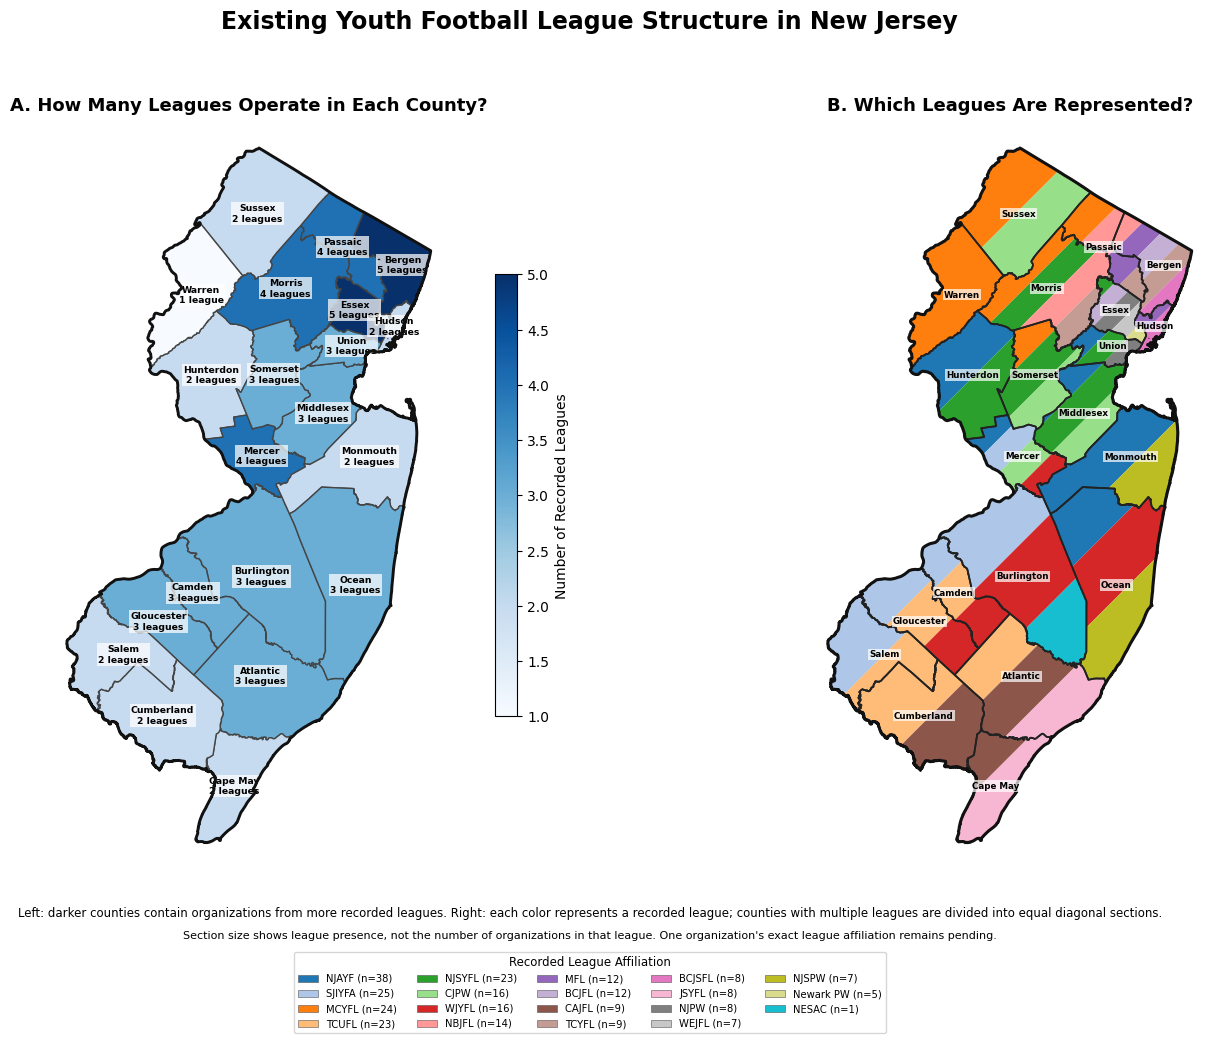

In [ ]:
# -------------------------------------------------------
# PS3 - MAP 2
# EXISTING LEAGUE STRUCTURE
# -------------------------------------------------------

from shapely.affinity import rotate
from shapely.geometry import box
from matplotlib.patches import Patch


# -------------------------------------------------------
# 1. PREPARE COUNTY LEAGUE COUNTS
# -------------------------------------------------------

league_map = (
    map_counties
    .rename(
        columns={"COUNTY": "GIS_County"}
    )
    .merge(
        league_by_county[
            ["GIS_County", "Verified_Leagues"]
        ],
        on="GIS_County",
        how="left"
    )
)

league_map["Verified_Leagues"] = (
    league_map["Verified_Leagues"]
    .fillna(0)
    .astype(int)
)


# -------------------------------------------------------
# 2. CREATE A CONSISTENT COLOR FOR EACH LEAGUE
#
# tab20 uses related dark/light color pairs.
# -------------------------------------------------------

league_counts = (
    verified_leagues["League_Acronym"]
    .value_counts()
)

league_order = (
    league_counts
    .index
    .tolist()
)

tab20 = plt.get_cmap("tab20")

league_colors = {
    league: tab20(i)
    for i, league in enumerate(league_order)
}


# -------------------------------------------------------
# 3. LIST THE LEAGUES PRESENT IN EACH COUNTY
# -------------------------------------------------------

order_lookup = {
    league: i
    for i, league in enumerate(league_order)
}

county_leagues = (
    verified_leagues
    .groupby("GIS_County")["League_Acronym"]
    .apply(
        lambda x: sorted(
            x.dropna().unique(),
            key=lambda league: order_lookup[league]
        )
    )
    .to_dict()
)


# -------------------------------------------------------
# 4. FUNCTION TO DIVIDE A COUNTY INTO
#    EQUAL DIAGONAL "/" SECTIONS
# -------------------------------------------------------

def diagonal_sections(geometry, number_of_sections):

    if number_of_sections <= 1:
        return [geometry]

    center = geometry.centroid
    origin = (center.x, center.y)

    # Rotate so vertical cuts become "/" cuts
    rotated = rotate(
        geometry,
        45,
        origin=origin
    )

    minx, miny, maxx, maxy = rotated.bounds

    width = (
        maxx - minx
    ) / number_of_sections

    padding = max(
        maxx - minx,
        maxy - miny
    ) * 0.05

    pieces = []

    for i in range(number_of_sections):

        x0 = minx + i * width
        x1 = minx + (i + 1) * width

        cutting_box = box(
            x0,
            miny - padding,
            x1,
            maxy + padding
        )

        piece = rotated.intersection(
            cutting_box
        )

        piece = rotate(
            piece,
            -45,
            origin=origin
        )

        pieces.append(piece)

    return pieces


# -------------------------------------------------------
# 5. CREATE SIDE-BY-SIDE FIGURE
# -------------------------------------------------------

fig, axes = plt.subplots(
    1,
    2,
    figsize=(18, 11)
)

ax1 = axes[0]
ax2 = axes[1]


# =======================================================
# LEFT MAP
# NUMBER OF LEAGUES PER COUNTY
# =======================================================

league_map.plot(
    ax=ax1,
    column="Verified_Leagues",
    cmap="Blues",
    edgecolor="#444444",
    linewidth=1.0,
    legend=True,
    legend_kwds={
        "label": "Number of Recorded Leagues",
        "shrink": 0.60
    }
)


league_map["label_point"] = (
    league_map.geometry
    .representative_point()
)


for _, row in league_map.iterrows():

    count = int(
        row["Verified_Leagues"]
    )

    league_word = (
        "league"
        if count == 1
        else "leagues"
    )

    ax1.text(
        row["label_point"].x,
        row["label_point"].y,

        f'{row["GIS_County"]}\n'
        f'{count} {league_word}',

        ha="center",
        va="center",

        fontsize=6.7,
        fontweight="bold",

        bbox=dict(
            facecolor="white",
            alpha=0.72,
            edgecolor="none",
            pad=1
        ),

        zorder=5
    )


# Strong state outline
league_map.dissolve().boundary.plot(
    ax=ax1,
    color="#111111",
    linewidth=2.1,
    zorder=6
)


ax1.set_title(
    "A. How Many Leagues Operate in Each County?",
    fontsize=13,
    fontweight="bold",
    pad=12
)

ax1.set_axis_off()


# =======================================================
# RIGHT MAP
# WHICH LEAGUES ARE REPRESENTED
# =======================================================

# Light background first
map_counties.plot(
    ax=ax2,
    color="#f4f4f4",
    edgecolor="none"
)


for _, county in map_counties.iterrows():

    county_name = county["COUNTY"]

    leagues = county_leagues.get(
        county_name,
        []
    )

    if len(leagues) == 0:
        continue

    pieces = diagonal_sections(
        county.geometry,
        len(leagues)
    )

    for piece, league in zip(
        pieces,
        leagues
    ):

        if piece.is_empty:
            continue

        gpd.GeoSeries(
            [piece],
            crs=map_counties.crs
        ).plot(
            ax=ax2,
            color=league_colors[league],
            edgecolor="none",
            zorder=2
        )


# -------------------------------------------------------
# COUNTY BOUNDARIES ON TOP
# -------------------------------------------------------

map_counties.boundary.plot(
    ax=ax2,
    color="#222222",
    linewidth=1.25,
    zorder=5
)


map_counties.dissolve().boundary.plot(
    ax=ax2,
    color="#111111",
    linewidth=2.2,
    zorder=6
)


# -------------------------------------------------------
# COUNTY LABELS
# -------------------------------------------------------

right_labels = map_counties.copy()

right_labels["label_point"] = (
    right_labels.geometry
    .representative_point()
)


for _, row in right_labels.iterrows():

    ax2.text(
        row["label_point"].x,
        row["label_point"].y,
        row["COUNTY"],

        ha="center",
        va="center",

        fontsize=6.3,
        fontweight="bold",

        bbox=dict(
            facecolor="white",
            alpha=0.70,
            edgecolor="none",
            pad=0.8
        ),

        zorder=7
    )


ax2.set_title(
    "B. Which Leagues Are Represented?",
    fontsize=13,
    fontweight="bold",
    pad=12
)

ax2.set_axis_off()


# -------------------------------------------------------
# 6. MAKE BOTH MAPS USE THE SAME EXTENT
# -------------------------------------------------------

minx, miny, maxx, maxy = (
    map_counties.total_bounds
)

x_padding = (
    maxx - minx
) * 0.05

y_padding = (
    maxy - miny
) * 0.03


for ax in axes:

    ax.set_xlim(
        minx - x_padding,
        maxx + x_padding
    )

    ax.set_ylim(
        miny - y_padding,
        maxy + y_padding
    )


# -------------------------------------------------------
# 7. LEAGUE LEGEND
# -------------------------------------------------------

legend_handles = [

    Patch(
        facecolor=league_colors[league],
        edgecolor="#555555",
        linewidth=0.4,
        label=(
            f"{league} "
            f"(n={league_counts[league]})"
        )
    )

    for league
    in league_order
]


fig.legend(
    handles=legend_handles,

    title="Recorded League Affiliation",

    loc="lower center",
    bbox_to_anchor=(0.5, 0.035),

    ncol=5,
    fontsize=7.2,
    title_fontsize=8.5,

    frameon=True
)


# -------------------------------------------------------
# 8. MAIN TITLE AND EXPLANATION
# -------------------------------------------------------

fig.suptitle(
    "Existing Youth Football League Structure in New Jersey",
    fontsize=17,
    fontweight="bold",
    y=0.97
)


fig.text(
    0.5,
    0.145,

    (
        "Left: darker counties contain organizations from more recorded leagues. "
        "Right: each color represents a recorded league; counties with multiple "
        "leagues are divided into equal diagonal sections."
    ),

    ha="center",
    fontsize=8.5
)


fig.text(
    0.5,
    0.125,

    (
        "Section size shows league presence, not the number of organizations in that league. "
        "One organization's exact league affiliation remains pending."
    ),

    ha="center",
    fontsize=8
)


plt.tight_layout(
    rect=[
        0,
        0.18,
        1,
        0.94
    ]
)

plt.show()

### Map 2 Interpretation

The 266 documented organizations participate in **19 recorded youth football leagues**, showing that coordination among independent community organizations already exists throughout New Jersey.

Existing leagues demonstrate that local organizations can work together within a larger structure to establish shared rules, schedules, expectations, communication, and other administrative functions. However, these coordinated systems are geographically divided. Different counties may contain several leagues, while individual leagues may extend across multiple county boundaries.

The two maps show this structure in different ways. The left map shows the number of recorded leagues represented within each county. Bergen and Essex have the greatest league diversity, with five recorded leagues each. The right map shows how those league networks overlap geographically across the state.

For the proposed NJYASA model, the importance of this finding is not that existing coordination is absent. Rather, it shows that **coordination already works at the league level**. NJYASA would examine whether similar principles could be extended statewide so that organizations operate within a more consistent administrative framework regardless of where they are located in New Jersey.

Under that concept, individual organizations could retain their local identity while families, volunteers, coaches, and organizational leaders would encounter more familiar standards, resources, and expectations when participating in youth sports elsewhere in the state.

One organization's exact league affiliation remains pending verification and is excluded from the verified league counts.

## Proposed NJYASA Regional Structure

The existing leagues show that independent organizations can already work together within a shared structure.

The next question is whether that same idea could be expanded across New Jersey.

The proposed NJYASA model divides the state into three regions:

- **North — 7 counties**
- **Central — 7 counties**
- **South — 7 counties**

These regions would not be separate football leagues. They would provide a consistent statewide framework for representation, administration, resources, and services.

The goal is to create a structure that remains familiar across the state while still allowing local organizations and communities to operate locally.

In [ ]:
# -------------------------------------------------------
# PS3 - PROPOSED NJYASA REGIONS
# -------------------------------------------------------

region_counties = {

    "North": [
        "Warren",
        "Bergen",
        "Essex",
        "Hudson",
        "Morris",
        "Passaic",
        "Sussex"
    ],

    "Central": [
        "Ocean",
        "Hunterdon",
        "Mercer",
        "Middlesex",
        "Monmouth",
        "Somerset",
        "Union"
    ],

    "South": [
        "Atlantic",
        "Burlington",
        "Camden",
        "Cape May",
        "Cumberland",
        "Gloucester",
        "Salem"
    ]
}


# Create county-to-region lookup
county_to_region = {
    county: region
    for region, county_list in region_counties.items()
    for county in county_list
}


# Assign every organization to a region
football_by_county["NJYASA_Region"] = (
    football_by_county["GIS_County"]
    .map(county_to_region)
)


# Check that every organization received a region
print(
    "Organizations without a region:",
    football_by_county["NJYASA_Region"].isna().sum()
)


# Regional summary
regional_summary = (
    football_by_county
    .groupby("NJYASA_Region")
    .agg(
        Organizations=("Program_ID", "count"),
        Counties=("GIS_County", "nunique")
    )
    .reindex(
        ["North", "Central", "South"]
    )
)


regional_summary["Statewide_Share"] = (
    regional_summary["Organizations"]
    / len(football_by_county)
    * 100
).round(1)


display(regional_summary)

Organizations without a region: 0


,Organizations,Counties,Statewide_Share
NJYASA_Region,,,
North,99,7,37.2
Central,89,7,33.5
South,78,7,29.3


## Map 3 — Proposed North, Central, and South Regions

This map tests a simple statewide structure made up of three seven-county regions.

Each point remains one documented youth football organization.

The map is intended to show whether the proposed regions create a reasonable geographic distribution of organizations across the state.

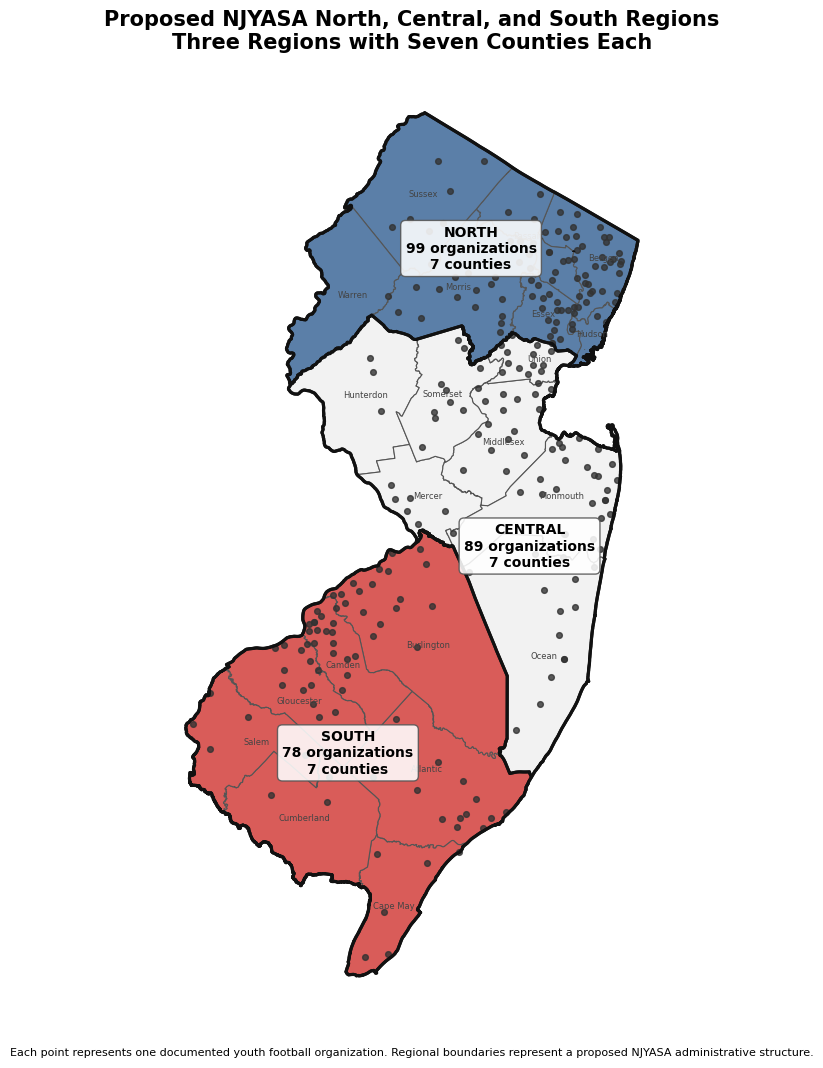

In [ ]:
# -------------------------------------------------------
# PS3 - MAP 3
# PROPOSED NORTH, CENTRAL, AND SOUTH REGIONS
# -------------------------------------------------------

# Add region to county map
region_map = map_counties.copy()

region_map["NJYASA_Region"] = (
    region_map["COUNTY"]
    .map(county_to_region)
)


# Region colors
region_colors = {
    "North": "#5b7fa8",
    "Central": "#f2f2f2",
    "South": "#d95c59"
}


# -------------------------------------------------------
# CREATE MAP
# -------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(9, 11)
)


for region in [
    "North",
    "Central",
    "South"
]:

    region_map[
        region_map["NJYASA_Region"] == region
    ].plot(
        ax=ax,
        color=region_colors[region],
        edgecolor="#555555",
        linewidth=0.8
    )


# Organization points
map_points.plot(
    ax=ax,
    color="#333333",
    markersize=17,
    alpha=0.80,
    zorder=3
)


# -------------------------------------------------------
# STRONG REGION BOUNDARIES
# -------------------------------------------------------

regional_boundaries = (
    region_map
    .dissolve(
        by="NJYASA_Region"
    )
)

regional_boundaries.boundary.plot(
    ax=ax,
    color="#111111",
    linewidth=2.2,
    zorder=4
)


# State outline
region_map.dissolve().boundary.plot(
    ax=ax,
    color="#111111",
    linewidth=2.3,
    zorder=5
)


# -------------------------------------------------------
# COUNTY LABELS
# -------------------------------------------------------

region_labels = region_map.copy()

region_labels["label_point"] = (
    region_labels.geometry
    .representative_point()
)


for _, row in region_labels.iterrows():

    ax.text(
        row["label_point"].x,
        row["label_point"].y,
        row["COUNTY"],

        ha="center",
        va="center",

        fontsize=6,
        color="#444444",

        zorder=6
    )


# -------------------------------------------------------
# REGION LABELS
# -------------------------------------------------------

for region in [
    "North",
    "Central",
    "South"
]:

    geometry = (
        regional_boundaries
        .loc[region]
        .geometry
    )

    label_point = (
        geometry
        .representative_point()
    )

    organization_count = int(
        regional_summary
        .loc[
            region,
            "Organizations"
        ]
    )

    ax.text(
        label_point.x,
        label_point.y,

        f"{region.upper()}\n"
        f"{organization_count} organizations\n"
        f"7 counties",

        ha="center",
        va="center",

        fontsize=10,
        fontweight="bold",

        bbox=dict(
            facecolor="white",
            alpha=0.88,
            edgecolor="#555555",
            boxstyle="round,pad=0.35"
        ),

        zorder=8
    )


# -------------------------------------------------------
# TITLE
# -------------------------------------------------------

ax.set_title(
    "Proposed NJYASA North, Central, and South Regions\n"
    "Three Regions with Seven Counties Each",
    fontsize=15,
    fontweight="bold",
    pad=15
)


fig.text(
    0.5,
    0.035,

    (
        "Each point represents one documented youth football organization. "
        "Regional boundaries represent a proposed NJYASA administrative structure."
    ),

    ha="center",
    fontsize=8
)


ax.set_axis_off()

plt.tight_layout(
    rect=[0, 0.055, 1, 1]
)

plt.show()

In [ ]:
# -------------------------------------------------------
# PS3 - LEAGUES ACROSS PROPOSED REGIONS
# -------------------------------------------------------

league_region = (
    verified_leagues
    .assign(
        NJYASA_Region=lambda df:
        df["GIS_County"].map(
            county_to_region
        )
    )
    .groupby("League_Acronym")
    .agg(
        Organizations=("Program_ID", "count"),
        Regions_Represented=("NJYASA_Region", "nunique")
    )
    .reset_index()
)


region_span_summary = (
    league_region[
        "Regions_Represented"
    ]
    .value_counts()
    .reindex(
        [1, 2, 3],
        fill_value=0
    )
    .rename_axis(
        "Regions"
    )
    .reset_index(
        name="Leagues"
    )
)


display(region_span_summary)

,Regions,Leagues
0,1,13
1,2,6
2,3,0


### Map 3 Interpretation

The proposed NJYASA structure divides New Jersey into three regions containing seven counties each.

The updated dataset places **99 documented organizations in North, 89 in Central, and 78 in South**. The regions therefore contain similar, but not equal, shares of the statewide network.

The county shading also shows that organizations are not distributed evenly within each region. Bergen County contains 36 documented organizations, while Warren County contains one. Burlington County contains 19 organizations, while Cumberland County contains four.

This is important because the proposed regions are intended to create a consistent statewide administrative structure, not three identical operating areas. Different counties and regions would still have different workloads and local needs.

The existing league structure also fits reasonably well with the proposed regional geography. Of the **19 verified leagues, 13 operate entirely within one proposed region, six operate across two regions, and none span all three**.

The regions shown are proposed administrative areas and have not been adopted by the organizations represented in the dataset.

## How Would Local Organizations Be Represented?

The proposed NJYASA model uses counties as the local level of representation.

Organizations located within the same county would participate in a **County Conference**. Each participating organization would have a voice in that conference, and the organizations would elect one **County Conference President**.

The elected County President would then represent the entire county on the Regional Council.

Because each proposed region contains seven counties, each Regional Council would contain **seven elected County Conference Presidents**.

This creates a bottom-up system in which statewide and regional decisions remain connected to people working with local organizations.

In [ ]:
# -------------------------------------------------------
# PS3 - COUNTY CONFERENCE STRUCTURE
# -------------------------------------------------------

county_conferences = (
    football_by_county
    .groupby("GIS_County")
    .agg(
        Organizations=("Program_ID", "count")
    )
    .reset_index()
)


# Assign each county to its proposed region
county_conferences["NJYASA_Region"] = (
    county_conferences["GIS_County"]
    .map(county_to_region)
)


# Each county receives one elected representative
county_conferences["Regional_Seats"] = 1


# Sort for easy reading
county_conferences = (
    county_conferences
    .sort_values(
        ["NJYASA_Region", "Organizations"],
        ascending=[True, False]
    )
    .reset_index(drop=True)
)


display(county_conferences)

,GIS_County,Organizations,NJYASA_Region,Regional_Seats
0,Monmouth,26,Central,1
1,Middlesex,16,Central,1
2,Ocean,14,Central,1
3,Union,14,Central,1
4,Somerset,10,Central,1
5,Mercer,6,Central,1
6,Hunterdon,3,Central,1
7,Bergen,36,North,1
8,Morris,21,North,1
9,Essex,18,North,1


In [ ]:
# -------------------------------------------------------
# PS3 - REGIONAL REPRESENTATION CHECK
# -------------------------------------------------------

regional_representation = (
    county_conferences
    .groupby("NJYASA_Region")
    .agg(
        County_Conferences=("GIS_County", "count"),
        Organizations=("Organizations", "sum"),
        Regional_Representatives=("Regional_Seats", "sum")
    )
    .reindex(
        ["North", "Central", "South"]
    )
)


display(regional_representation)

,County_Conferences,Organizations,Regional_Representatives
NJYASA_Region,,,
North,7,99,7
Central,7,89,7
South,7,78,7


## Map 4 — Proposed County Conference Representation

This map shows how the 266 documented organizations would be represented under the proposed County Conference model.

Counties are shaded by the number of documented organizations they contain.

Each county would still elect **one County Conference President**, regardless of the number of organizations in that county. The seven County Presidents in each region would together form the Regional Council.

## How Would Local Organizations Be Represented?

The proposed NJYASA model uses counties as the local level of representation.

Organizations within each county would participate in a **County Conference** and select one **County Conference President**.

The number of organizations represented by each County Conference would vary. However, each county would receive one representative on its Regional Council.

Because each proposed region contains seven counties, each Regional Council would contain **seven elected County Conference Presidents**.

In [ ]:
# -------------------------------------------------------
# PS3 - COUNTY CONFERENCE STRUCTURE
# -------------------------------------------------------

county_conferences = (
    football_by_county
    .groupby("GIS_County")
    .agg(
        Organizations=("Program_ID", "count")
    )
    .reset_index()
)

county_conferences["NJYASA_Region"] = (
    county_conferences["GIS_County"]
    .map(county_to_region)
)

county_conferences["Regional_Seat"] = 1


regional_representation = (
    county_conferences
    .groupby("NJYASA_Region")
    .agg(
        Counties=("GIS_County", "count"),
        Organizations=("Organizations", "sum"),
        Representatives=("Regional_Seat", "sum")
    )
    .reindex(["North", "Central", "South"])
)

display(regional_representation)

,Counties,Organizations,Representatives
NJYASA_Region,,,
North,7,99,7
Central,7,89,7
South,7,78,7


## Map 4 — County Conference Size and Regional Representation

The two maps compare two different parts of the proposed governance system.

The left map shows how many organizations each County Conference would represent.

The right map shows the representation structure: each county would elect one County Conference President, giving every county one seat on its Regional Council.

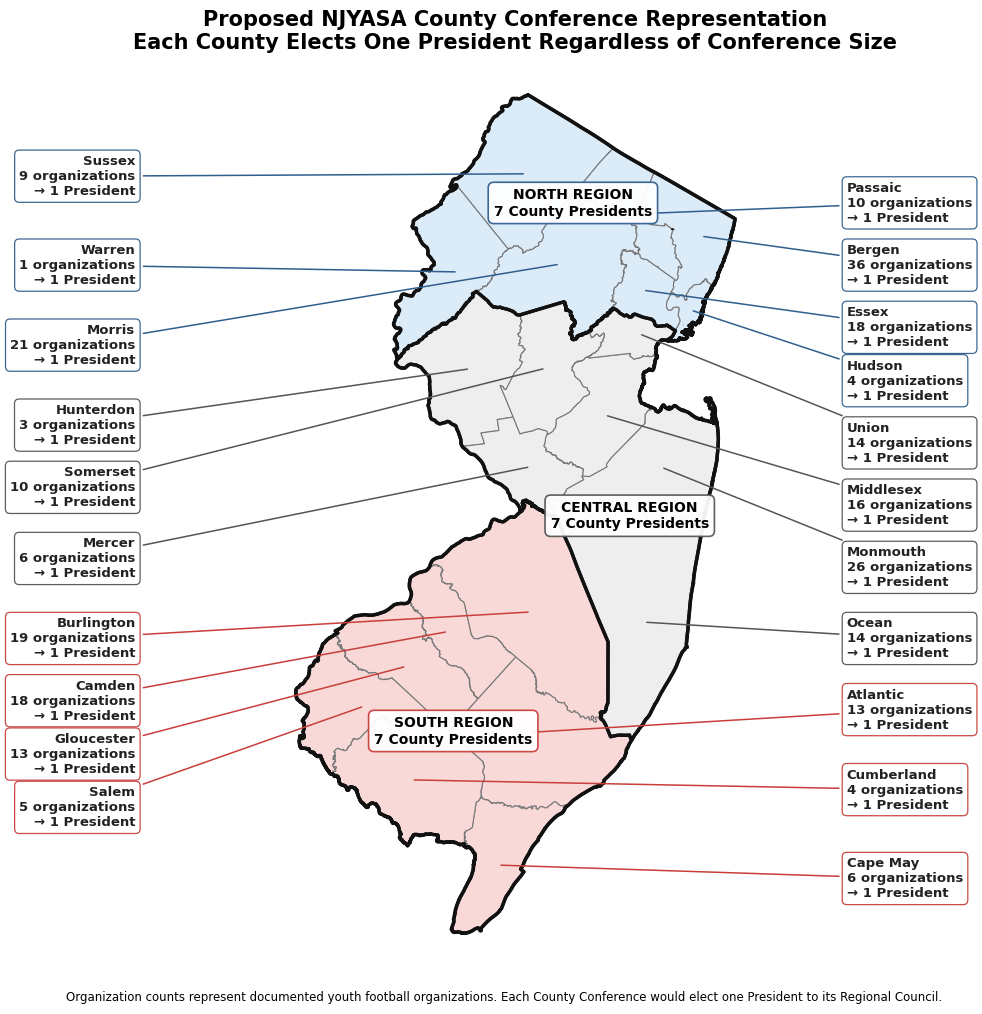

In [ ]:
# -------------------------------------------------------
# PS3 - MAP 4
# COUNTY CONFERENCE REPRESENTATION
# -------------------------------------------------------

# Prepare county conference map
conference_map = (
    map_counties
    .rename(columns={"COUNTY": "GIS_County"})
    .merge(
        county_conferences,
        on="GIS_County",
        how="left"
    )
)


# -------------------------------------------------------
# REGION COLORS
# -------------------------------------------------------

region_fill = {
    "North": "#dcebf8",
    "Central": "#eeeeee",
    "South": "#f8d9d7"
}

region_line = {
    "North": "#315f8d",
    "Central": "#555555",
    "South": "#c83f3b"
}


# -------------------------------------------------------
# CREATE MAP
# -------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(12, 11)
)


# Draw counties by region
for region in ["North", "Central", "South"]:

    subset = conference_map[
        conference_map["NJYASA_Region"] == region
    ]

    subset.plot(
        ax=ax,
        color=region_fill[region],
        edgecolor="#777777",
        linewidth=0.8
    )


# -------------------------------------------------------
# STRONG REGIONAL BOUNDARIES
# -------------------------------------------------------

conference_regions = (
    conference_map
    .dissolve(by="NJYASA_Region")
)

conference_regions.boundary.plot(
    ax=ax,
    color="#111111",
    linewidth=2.4,
    zorder=5
)


conference_map.dissolve().boundary.plot(
    ax=ax,
    color="#111111",
    linewidth=2.5,
    zorder=6
)


# -------------------------------------------------------
# OUTSIDE LABEL LOCATIONS
# -------------------------------------------------------

label_positions = {

    # NORTH - LEFT
    "Sussex":      (0.03, 0.88),
    "Warren":      (0.03, 0.78),
    "Morris":      (0.03, 0.69),

    # NORTH - RIGHT
    "Passaic":     (0.91, 0.85),
    "Bergen":      (0.91, 0.78),
    "Essex":       (0.91, 0.71),
    "Hudson":      (0.91, 0.65),

    # CENTRAL - LEFT
    "Hunterdon":   (0.03, 0.60),
    "Somerset":    (0.03, 0.53),
    "Mercer":      (0.03, 0.45),

    # CENTRAL - RIGHT
    "Union":       (0.91, 0.58),
    "Middlesex":   (0.91, 0.51),
    "Monmouth":    (0.91, 0.44),
    "Ocean":       (0.91, 0.36),

    # SOUTH - LEFT
    "Burlington":  (0.03, 0.36),
    "Camden":      (0.03, 0.29),
    "Gloucester":  (0.03, 0.23),
    "Salem":       (0.03, 0.17),

    # SOUTH - RIGHT
    "Atlantic":    (0.91, 0.28),
    "Cumberland":  (0.91, 0.19),
    "Cape May":    (0.91, 0.09)
}


# -------------------------------------------------------
# COUNTY LABELS
# ORGANIZATIONS -> ONE PRESIDENT
# -------------------------------------------------------

for _, row in conference_map.iterrows():

    county = row["GIS_County"]
    region = row["NJYASA_Region"]

    point = (
        row.geometry
        .representative_point()
    )

    label_x, label_y = (
        label_positions[county]
    )

    count = int(
        row["Organizations"]
    )


    ax.annotate(

        f"{county}\n"
        f"{count} organizations\n"
        "→ 1 President",

        xy=(
            point.x,
            point.y
        ),

        xycoords="data",

        xytext=(
            label_x,
            label_y
        ),

        textcoords="axes fraction",

        ha=(
            "left"
            if label_x > 0.5
            else "right"
        ),

        va="center",

        fontsize=9.5,
        fontweight="bold",

        color="#222222",

        bbox=dict(
            facecolor="white",
            edgecolor=region_line[region],
            linewidth=0.9,
            alpha=0.95,
            boxstyle="round,pad=0.35"
        ),

        arrowprops=dict(
            arrowstyle="-",
            color=region_line[region],
            linewidth=1.1,
            shrinkA=2,
            shrinkB=2
        ),

        zorder=10
    )


# -------------------------------------------------------
# REGIONAL COUNCIL LABELS
# -------------------------------------------------------

regional_label_offsets = {
    "North": (0, 25000),
    "Central": (0, 0),
    "South": (0, -15000)
}


for region in ["North", "Central", "South"]:

    geometry = (
        conference_regions
        .loc[region]
        .geometry
    )

    point = (
        geometry
        .representative_point()
    )

    dx, dy = (
        regional_label_offsets[region]
    )


    ax.text(
        point.x + dx,
        point.y + dy,

        f"{region.upper()} REGION\n"
        "7 County Presidents",

        ha="center",
        va="center",

        fontsize=10,
        fontweight="bold",

        bbox=dict(
            facecolor="white",
            edgecolor=region_line[region],
            linewidth=1.2,
            alpha=0.94,
            boxstyle="round,pad=0.40"
        ),

        zorder=12
    )


# -------------------------------------------------------
# TITLE
# -------------------------------------------------------

ax.set_title(
    "Proposed NJYASA County Conference Representation\n"
    "Each County Elects One President Regardless of Conference Size",
    fontsize=15,
    fontweight="bold",
    pad=15
)


# -------------------------------------------------------
# MAP NOTE
# -------------------------------------------------------

fig.text(
    0.5,
    0.035,

    (
        "Organization counts represent documented youth football organizations. "
        "Each County Conference would elect one President to its Regional Council."
    ),

    ha="center",
    fontsize=8.5
)


# -------------------------------------------------------
# MAP EXTENT
# -------------------------------------------------------

minx, miny, maxx, maxy = (
    conference_map.total_bounds
)

x_padding = (
    maxx - minx
) * 0.42

y_padding = (
    maxy - miny
) * 0.03


ax.set_xlim(
    minx - x_padding,
    maxx + x_padding
)

ax.set_ylim(
    miny - y_padding,
    maxy + y_padding
)


ax.set_axis_off()

plt.tight_layout(
    rect=[0, 0.06, 1, 0.95]
)

plt.show()

### Map 4 Interpretation

The proposed County Conference model separates organizational workload from regional representation.

County Conferences would represent very different numbers of organizations. Bergen County would represent 36 documented organizations, while Warren County would represent one. Burlington County would represent 19 organizations.

However, each County Conference would elect one President. Because each proposed region contains seven counties, the North, Central, and South Regional Councils would each contain seven elected County Presidents.

This creates a bottom-up representative structure. Local organizations select their county representative, and the seven County Presidents collectively represent the region.

The County Presidents would provide local knowledge, priorities, and accountability. They would not be expected to carry out the full administrative workload of NJYASA. Professional staff would be responsible for statewide and regional operations, partnerships, programs, and service coordination. Equal county representation would not imply equal resource allocation or a fixed number of organizations. County Conferences could grow as additional eligible community organizations are formed, while programs and resources could be distributed according to participation, need, and other relevant measures.

## Where Could NJYASA Find Professional and Educational Partners?

The County Conference structure provides local representation, but volunteers would not be expected to operate the entire statewide system.

NJYASA would need professional staff and outside partners to help deliver programs, training, internships, research, and other services.

New Jersey colleges and universities are one possible part of that network.

This section first examines **where higher-education institutions are located** before deciding what specific role any institution could play.

### Higher-Education Data

The institution list will be based on the **New Jersey Office of the Secretary of Higher Education (OSHE)**.

For this first map, institutions will be grouped into simple categories such as:

- Community colleges
- Public four-year colleges and universities
- Independent/private four-year colleges and universities

Later analysis can examine which institutions offer academic programs or facilities that could support specific NJYASA services.

## Where Could NJYASA Find Institutional Partners?

The County Conference structure provides local representation, but volunteers would not be expected to operate the entire statewide system.

NJYASA would need professional staff and outside partners to help provide training, internships, research, education, and other services.

New Jersey's colleges and universities are one potential part of that network.

The first step is to identify where higher-education institutions are located throughout the state. Specific partnership roles will be examined later rather than assumed in advance.

### Higher-Education Data

The statewide college inventory is based on the **New Jersey Office of the Secretary of Higher Education (OSHE)**.

OSHE identifies New Jersey institutions by:

- college or university
- county
- two-year or four-year status
- public or private status

This allows the project to examine higher education as an existing statewide network before identifying individual institutions that may have relevant programs or facilities.

In [ ]:
# -------------------------------------------------------
# PS3 - NEW JERSEY HIGHER EDUCATION
# -------------------------------------------------------

OSHE_COLLEGE_URL = (
    "https://www.nj.gov/highereducation/"
    "CollegeForYou/find-colleges.shtml"
)

# Read tables from the official OSHE page
oshe_tables = pd.read_html(OSHE_COLLEGE_URL)

print("Tables found:", len(oshe_tables))

Tables found: 1


In [ ]:
# -------------------------------------------------------
# PS3 - FIND OSHE COLLEGE DIRECTORY
# -------------------------------------------------------

college_table = None

for table in oshe_tables:

    if {
        "College",
        "County",
        "Years",
        "Type"
    }.issubset(table.columns):

        college_table = table.copy()
        break


if college_table is None:

    raise ValueError(
        "The OSHE college directory table was not found."
    )


print(
    "Institutions listed:",
    len(college_table)
)

display(
    college_table.head(10)
)

Institutions listed: 53


,College,County,Years,Type
0,Atlantic Cape Community College,Atlantic,Two-Year,Public
1,Stockton University,Atlantic,Four-Year,Public
2,Bergen Community College,Bergen,Two-Year,Public
3,Eastwick College,Bergen,Two-Year,Public
4,Fairleigh Dickinson University - Metropolitan ...,Bergen,Four-Year,Private
5,Felician University,Bergen,Four-Year,Private
6,Ramapo College of New Jersey,Bergen,Four-Year,Public
7,Rowan College at Burlington County,Burlington,Two-Year,Public
8,Camden County College,Camden,Two-Year,Public
9,Rutgers University–Camden,Camden,Four-Year,Public


In [ ]:
# -------------------------------------------------------
# PS3 - CLEAN HIGHER-EDUCATION TABLE
# -------------------------------------------------------

colleges = college_table[
    [
        "College",
        "County",
        "Years",
        "Type"
    ]
].copy()


# Clean text
for column in [
    "College",
    "County",
    "Years",
    "Type"
]:

    colleges[column] = (
        colleges[column]
        .astype(str)
        .str.strip()
    )


# Remove exact duplicates if the webpage contains any
colleges = (
    colleges
    .drop_duplicates()
    .reset_index(drop=True)
)


print(
    "Institutions:",
    len(colleges)
)

print(
    "Counties represented:",
    colleges["County"].nunique()
)

print()

print("By institution length:")
display(
    colleges["Years"]
    .value_counts()
    .rename("Institutions")
)

print()

print("By public/private type:")
display(
    colleges["Type"]
    .value_counts()
    .rename("Institutions")
)

Institutions: 53
Counties represented: 21

By institution length:


,Institutions
Years,
Four-Year,31
Two-Year,22



By public/private type:


,Institutions
Type,
Public,35
Private,18


In [ ]:
# -------------------------------------------------------
# PS3 - COLLEGES BY COUNTY
# -------------------------------------------------------

college_county_summary = (
    colleges
    .groupby("County")
    .agg(
        Institutions=("College", "count"),
        Two_Year=(
            "Years",
            lambda x: (x == "Two-Year").sum()
        ),
        Four_Year=(
            "Years",
            lambda x: (x == "Four-Year").sum()
        )
    )
    .reset_index()
    .sort_values(
        "Institutions",
        ascending=False
    )
    .reset_index(drop=True)
)

display(college_county_summary)

,County,Institutions,Two_Year,Four_Year
0,Essex,8,1,7
1,Mercer,5,1,4
2,Bergen,5,2,3
3,Morris,4,1,3
4,Hudson,4,1,3
5,Passaic,3,1,2
6,Middlesex,3,1,2
7,Camden,2,1,1
8,Atlantic,2,1,1
9,Union,2,1,1


In [ ]:
# -------------------------------------------------------
# PS3 - HIGHER EDUCATION BY TYPE
# -------------------------------------------------------

college_type_summary = pd.crosstab(
    colleges["Years"],
    colleges["Type"]
)

display(college_type_summary)

Type,Private,Public
Years,,
Four-Year,18,13
Two-Year,0,22


In [ ]:
# -------------------------------------------------------
# PS3 - HIGHER EDUCATION BY NJYASA REGION
# -------------------------------------------------------

colleges["NJYASA_Region"] = (
    colleges["County"]
    .map(county_to_region)
)

higher_ed_regions = (
    colleges
    .groupby("NJYASA_Region")
    .agg(
        Institutions=("College", "count"),
        Two_Year=("Years", lambda x: (x == "Two-Year").sum()),
        Four_Year=("Years", lambda x: (x == "Four-Year").sum()),
        Public=("Type", lambda x: (x == "Public").sum()),
        Private=("Type", lambda x: (x == "Private").sum())
    )
    .reindex(["North", "Central", "South"])
)

display(higher_ed_regions)

,Institutions,Two_Year,Four_Year,Public,Private
NJYASA_Region,,,,,
North,27,8,19,14,13
Central,16,7,9,11,5
South,10,7,3,10,0


## Map 5 — Higher Education as a Potential Service-Delivery Network

The proposed NJYASA structure would rely on local representation, professional staff, and outside institutional partnerships.

Higher education could support this model at two different geographic levels.

**Community colleges** provide a potential county-level network. New Jersey's 18 community colleges collectively serve all 21 counties, including several colleges that serve more than one county.

**Four-year colleges and universities** provide a potential regional network with additional academic, research, athletic, internship, and professional capacity.

The institutions shown are potential resources only. Their presence does not imply that any institution has agreed to partner with NJYASA.

In [ ]:
# -------------------------------------------------------
# PS3 - HIGHER EDUCATION SERVICE NETWORK
# -------------------------------------------------------

# Community college service areas
community_service = {
    "Atlantic Cape Community College":
        ["Atlantic", "Cape May"],

    "Bergen Community College":
        ["Bergen"],

    "Brookdale Community College":
        ["Monmouth"],

    "Camden County College":
        ["Camden"],

    "County College of Morris":
        ["Morris"],

    "Essex County College":
        ["Essex"],

    "Hudson County Community College":
        ["Hudson"],

    "Mercer County Community College":
        ["Mercer"],

    "Middlesex College":
        ["Middlesex"],

    "Ocean County College":
        ["Ocean"],

    "Passaic County Community College":
        ["Passaic"],

    "Raritan Valley Community College":
        ["Hunterdon", "Somerset"],

    "Rowan College at Burlington County":
        ["Burlington"],

    "Rowan College of South Jersey":
        ["Gloucester", "Cumberland"],

    "Salem Community College":
        ["Salem"],

    "Sussex County Community College":
        ["Sussex"],

    "UCNJ Union College of Union County":
        ["Union"],

    "Warren County Community College":
        ["Warren"]
}


# -------------------------------------------------------
# FOUR-YEAR COLLEGES AND UNIVERSITIES
# Use the official OSHE table directly
# -------------------------------------------------------

four_year = (
    colleges.loc[
        colleges["Years"] == "Four-Year",
        [
            "College",
            "County",
            "Type"
        ]
    ]
    .rename(
        columns={
            "College": "Institution"
        }
    )
    .copy()
    .reset_index(drop=True)
)


# Assign each institution to a proposed NJYASA region
four_year["NJYASA_Region"] = (
    four_year["County"]
    .map(county_to_region)
)


# -------------------------------------------------------
# QUALITY CHECK
# -------------------------------------------------------

print(
    "Four-year institutions:",
    len(four_year)
)

print(
    "Institutions without a region:",
    four_year["NJYASA_Region"].isna().sum()
)

print()

print("Four-year institutions by proposed region:")

display(
    four_year["NJYASA_Region"]
    .value_counts()
    .reindex(
        ["North", "Central", "South"]
    )
    .rename("Institutions")
)

Four-year institutions: 31
Institutions without a region: 0

Four-year institutions by proposed region:


,Institutions
NJYASA_Region,
North,19
Central,9
South,3


In [ ]:
# -------------------------------------------------------
# PS3 - CHECK FOUR-YEAR INSTITUTION COVERAGE
# -------------------------------------------------------

official_four_year = (
    colleges.loc[
        colleges["Years"] == "Four-Year",
        ["College", "County", "Type"]
    ]
    .copy()
)

mapped_names = set(
    four_year["Institution"]
)

official_names = set(
    official_four_year["College"]
)


assert len(four_year) == 31

assert (
    four_year["NJYASA_Region"]
    .notna()
    .all()
)

print(
    "All official OSHE four-year institutions "
    "are included in the regional dataset."
)

All official OSHE four-year institutions are included in the regional dataset.


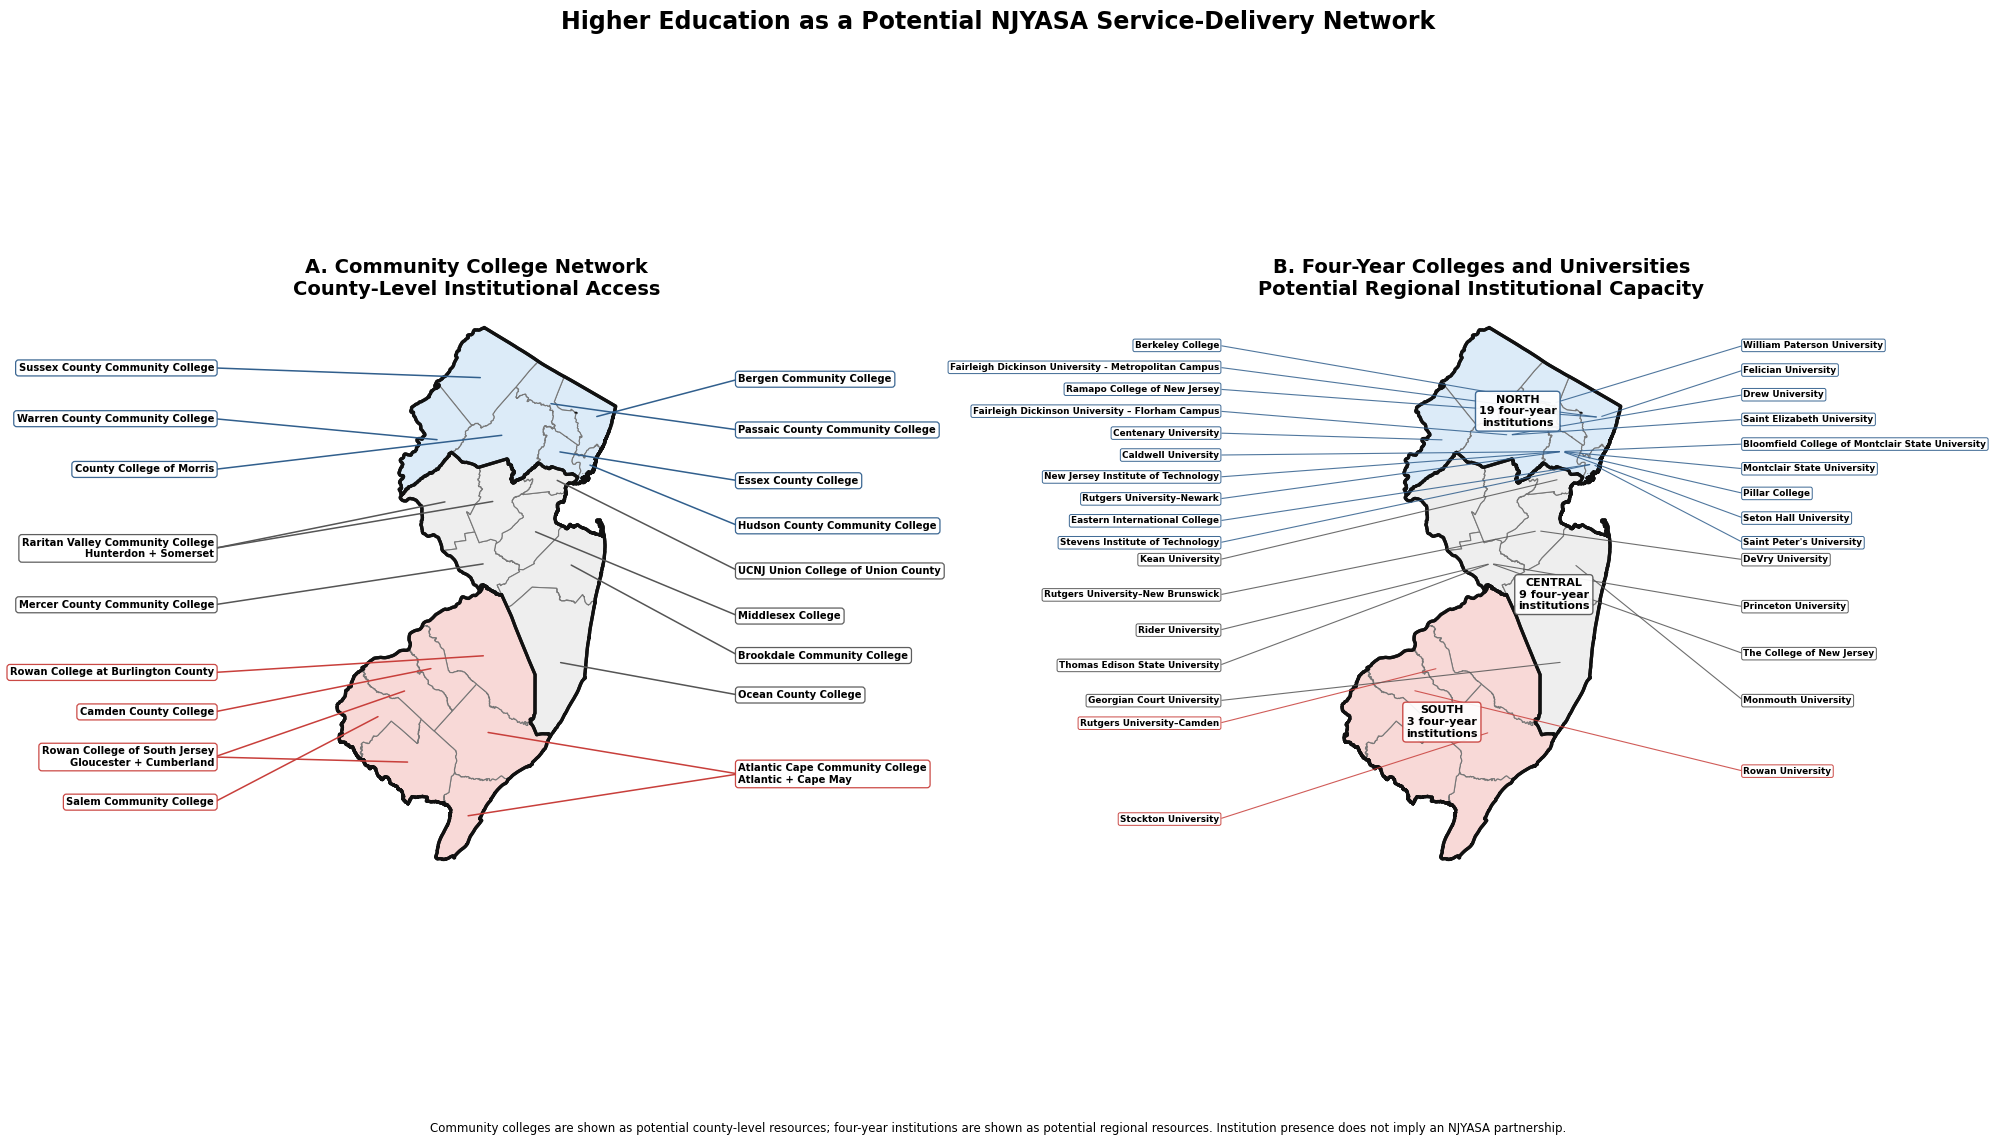

In [ ]:
# -------------------------------------------------------
# PS3 - MAP 5
# HIGHER EDUCATION SERVICE NETWORK
# -------------------------------------------------------

higher_ed_base = (
    map_counties
    .rename(columns={"COUNTY": "County"})
    .copy()
)

higher_ed_base["NJYASA_Region"] = (
    higher_ed_base["County"]
    .map(county_to_region)
)


region_fill = {
    "North": "#dcebf8",
    "Central": "#eeeeee",
    "South": "#f8d9d7"
}

region_line = {
    "North": "#315f8d",
    "Central": "#555555",
    "South": "#c83f3b"
}


# County reference points
county_points = {
    row["County"]: row.geometry.representative_point()
    for _, row in higher_ed_base.iterrows()
}


# -------------------------------------------------------
# FIGURE
# -------------------------------------------------------

fig, axes = plt.subplots(
    1,
    2,
    figsize=(20, 12)
)

ax1, ax2 = axes


# -------------------------------------------------------
# BACKGROUND FOR BOTH MAPS
# -------------------------------------------------------

for ax in axes:

    for region in ["North", "Central", "South"]:

        higher_ed_base[
            higher_ed_base["NJYASA_Region"] == region
        ].plot(
            ax=ax,
            color=region_fill[region],
            edgecolor="#777777",
            linewidth=0.8
        )

    higher_ed_base.dissolve(
        by="NJYASA_Region"
    ).boundary.plot(
        ax=ax,
        color="#111111",
        linewidth=2.3,
        zorder=5
    )

    higher_ed_base.dissolve().boundary.plot(
        ax=ax,
        color="#111111",
        linewidth=2.4,
        zorder=6
    )

    ax.set_axis_off()


# =======================================================
# PANEL A
# COMMUNITY COLLEGES
# =======================================================

community_positions = {

    "Sussex County Community College": (0.02, 0.90),
    "Warren County Community College": (0.02, 0.81),
    "County College of Morris": (0.02, 0.72),

    "Raritan Valley Community College": (0.02, 0.58),
    "Mercer County Community College": (0.02, 0.48),

    "Rowan College at Burlington County": (0.02, 0.36),
    "Camden County College": (0.02, 0.29),
    "Rowan College of South Jersey": (0.02, 0.21),
    "Salem Community College": (0.02, 0.13),

    "Bergen Community College": (0.98, 0.88),
    "Passaic County Community College": (0.98, 0.79),
    "Essex County College": (0.98, 0.70),
    "Hudson County Community College": (0.98, 0.62),

    "UCNJ Union College of Union County": (0.98, 0.54),
    "Middlesex College": (0.98, 0.46),
    "Brookdale Community College": (0.98, 0.39),
    "Ocean County College": (0.98, 0.32),

    "Atlantic Cape Community College": (0.98, 0.18)
}


for college, served_counties in community_service.items():

    label_x, label_y = community_positions[college]

    region = county_to_region[
        served_counties[0]
    ]

    # Short explanation for multi-county colleges
    if len(served_counties) > 1:

        county_text = (
            " + ".join(served_counties)
        )

        label = (
            f"{college}\n"
            f"{county_text}"
        )

    else:

        label = college


    # Draw the label
    ax1.text(
        label_x,
        label_y,
        label,

        transform=ax1.transAxes,

        ha="left" if label_x > 0.5 else "right",
        va="center",

        fontsize=7.2,
        fontweight="bold",

        bbox=dict(
            facecolor="white",
            edgecolor=region_line[region],
            linewidth=0.9,
            alpha=0.95,
            boxstyle="round,pad=0.30"
        ),

        zorder=10
    )


    # One line to every county the college serves
    for county in served_counties:

        point = county_points[county]

        ax1.annotate(
            "",

            xy=(point.x, point.y),
            xycoords="data",

            xytext=(label_x, label_y),
            textcoords="axes fraction",

            arrowprops=dict(
                arrowstyle="-",
                color=region_line[region],
                linewidth=1.1
            ),

            zorder=8
        )


ax1.set_title(
    "A. Community College Network\n"
    "County-Level Institutional Access",
    fontsize=14,
    fontweight="bold",
    pad=12
)


# =======================================================
# PANEL B
# FOUR-YEAR COLLEGES AND UNIVERSITIES
# =======================================================

# County reference coordinates for sorting labels
four_year["Anchor_X"] = (
    four_year["County"]
    .map(lambda x: county_points[x].x)
)

four_year["Anchor_Y"] = (
    four_year["County"]
    .map(lambda x: county_points[x].y)
)


# Region label zones
region_y_ranges = {
    "North": (0.94, 0.59),
    "Central": (0.56, 0.31),
    "South": (0.27, 0.10)
}


label_locations = {}


for region in ["North", "Central", "South"]:

    subset = (
        four_year[
            four_year["NJYASA_Region"] == region
        ]
        .sort_values(
            ["Anchor_Y", "Institution"],
            ascending=[False, True]
        )
        .reset_index(drop=True)
    )

    left = subset.iloc[::2]
    right = subset.iloc[1::2]

    y_top, y_bottom = (
        region_y_ranges[region]
    )


    left_y = (
        [sum((y_top, y_bottom)) / 2]
        if len(left) == 1
        else list(
            __import__("numpy").linspace(
                y_top,
                y_bottom,
                len(left)
            )
        )
    )

    right_y = (
        [sum((y_top, y_bottom)) / 2]
        if len(right) == 1
        else list(
            __import__("numpy").linspace(
                y_top,
                y_bottom,
                len(right)
            )
        )
    )


    for (_, row), y in zip(
        left.iterrows(),
        left_y
    ):

        label_locations[row["Institution"]] = (
            0.02,
            y
        )


    for (_, row), y in zip(
        right.iterrows(),
        right_y
    ):

        label_locations[row["Institution"]] = (
            0.98,
            y
        )


# Draw institution names and leader lines
for _, row in four_year.iterrows():

    institution = row["Institution"]
    county = row["County"]
    region = row["NJYASA_Region"]

    point = county_points[county]

    label_x, label_y = (
        label_locations[institution]
    )


    ax2.text(
        label_x,
        label_y,
        institution,

        transform=ax2.transAxes,

        ha="left" if label_x > 0.5 else "right",
        va="center",

        fontsize=6.4,
        fontweight="bold",

        bbox=dict(
            facecolor="white",
            edgecolor=region_line[region],
            linewidth=0.7,
            alpha=0.95,
            boxstyle="round,pad=0.20"
        ),

        zorder=10
    )


    ax2.annotate(
        "",

        xy=(point.x, point.y),
        xycoords="data",

        xytext=(label_x, label_y),
        textcoords="axes fraction",

        arrowprops=dict(
            arrowstyle="-",
            color=region_line[region],
            linewidth=0.8,
            alpha=0.85
        ),

        zorder=8
    )


# Region summary boxes
four_year_counts = (
    four_year["NJYASA_Region"]
    .value_counts()
)

region_shapes = (
    higher_ed_base
    .dissolve(by="NJYASA_Region")
)


for region in ["North", "Central", "South"]:

    point = (
        region_shapes
        .loc[region]
        .geometry
        .representative_point()
    )

    ax2.text(
        point.x,
        point.y,

        f"{region.upper()}\n"
        f"{four_year_counts[region]} four-year\n"
        f"institutions",

        ha="center",
        va="center",

        fontsize=8,
        fontweight="bold",

        bbox=dict(
            facecolor="white",
            edgecolor=region_line[region],
            alpha=0.92,
            boxstyle="round,pad=0.30"
        ),

        zorder=12
    )


ax2.set_title(
    "B. Four-Year Colleges and Universities\n"
    "Potential Regional Institutional Capacity",
    fontsize=14,
    fontweight="bold",
    pad=12
)


# -------------------------------------------------------
# MAP EXTENT
# -------------------------------------------------------

minx, miny, maxx, maxy = (
    higher_ed_base.total_bounds
)

x_padding = (
    maxx - minx
) * 0.48

y_padding = (
    maxy - miny
) * 0.03


for ax in axes:

    ax.set_xlim(
        minx - x_padding,
        maxx + x_padding
    )

    ax.set_ylim(
        miny - y_padding,
        maxy + y_padding
    )


# -------------------------------------------------------
# MAIN TITLE
# -------------------------------------------------------

fig.suptitle(
    "Higher Education as a Potential NJYASA Service-Delivery Network",
    fontsize=17,
    fontweight="bold",
    y=0.97
)


fig.text(
    0.5,
    0.035,

    (
        "Community colleges are shown as potential county-level resources; "
        "four-year institutions are shown as potential regional resources. "
        "Institution presence does not imply an NJYASA partnership."
    ),

    ha="center",
    fontsize=8.5
)


plt.tight_layout(
    rect=[0, 0.06, 1, 0.94]
)

plt.show()

### Map 5 Interpretation

New Jersey already has a statewide network of colleges and universities that could provide potential resources and opportunities for the proposed NJYASA structure.

The left map shows the community-college network. Community colleges could serve as potential county-level resource hubs because their service areas collectively reach all 21 New Jersey counties. Some institutions already serve more than one county, including Raritan Valley Community College, Atlantic Cape Community College, and Rowan College of South Jersey.

The right map shows four-year colleges and universities within the proposed North, Central, and South regions. The official OSHE directory identifies 19 four-year institutions in North, 9 in Central, and 3 in South.

These institutions could potentially provide different kinds of resources depending on their programs, facilities, students, faculty, and community partnerships. Examples could include internships, workforce development, research, training, communications, professional expertise, facilities, and other opportunities.

The purpose of the map is not to recommend a specific college or university partnership. It shows that NJYASA would be operating within an existing statewide higher-education network that could be used differently according to regional and local needs.

Institution presence does not imply an existing or proposed partnership with NJYASA.

# Conclusion

This project examined whether a county-based and regional structure could provide a practical way to coordinate New Jersey youth football organizations statewide while maintaining local representation.

The analysis identified **266 documented youth football organizations across all 21 New Jersey counties**. These organizations already participate in multiple leagues that coordinate programs across municipal and county boundaries. This demonstrates that coordinated organization is already part of youth football in New Jersey, although the current structure varies depending on location and league affiliation.

A proposed NJYASA structure could organize this statewide network through **21 County Conferences and three regions: North, Central, and South**. Each County Conference would be made up of its local youth football organizations and would elect one County President. Because each proposed region contains seven counties, each Regional Council would contain seven County Presidents.

This approach creates a bottom-up system of representation. Local organizations would have a direct role in selecting their county representative, while professional NJYASA staff could handle the larger administrative, partnership, and statewide responsibilities instead of placing those responsibilities on local volunteers.

The higher-education analysis also shows that this proposed structure would operate within an existing statewide network of community colleges and four-year colleges and universities. These institutions could provide potential resources and opportunities at the county and regional levels without requiring NJYASA to develop every resource internally.

Overall, the GIS analysis suggests that a statewide coordinating structure is geographically possible. The proposed model provides a way to connect local organizations, counties, regions, professional staff, and existing institutional resources while preserving local participation in decision-making.

# Limitations

This project is based on documented youth football organizations and their mapped home-field locations. The dataset does not measure the number of athletes, number of teams, registration levels, financial resources, or the full geographic area served by each organization.

League affiliation represents the best documented information available during the research period. One organization's exact league affiliation remains pending verification.

The proposed County Conference and North, Central, and South regional structure is a planning model developed for this project. These boundaries do not represent an existing NJYASA administrative system.

Organization counts should also not be interpreted as measures of participation or need. A county with fewer documented organizations may still serve a large number of athletes, while a county with many organizations may divide participation among several smaller programs.

The higher-education analysis identifies existing institutions as possible resources and opportunity hubs. Their presence does not indicate that any college or university has agreed to participate in or partner with NJYASA.

# Next Steps

PS3 establishes the geographic and organizational foundation of the proposed NJYASA model.

The next stage of the project will examine how this structure could connect with existing New Jersey public institutions and programs.

PS4 will specifically examine the potential relationship between NJYASA and:

- the **New Jersey Department of State**
- the **New Jersey Department of Children and Families**
- the **New Jersey Department of Community Affairs**

The purpose will be to determine whether an organized statewide youth-sports network could help connect state resources with local organizations while also creating a structured pathway for local needs and information to move upward through County Conferences, Regional Councils, and NJYASA professional staff.

Later analysis can also examine additional measures such as population, youth population, school districts, recreation infrastructure, participation, facilities, and other indicators of local need and capacity.